# 02. 전처리·Dataset·평가 함수와 학습 시간 측정(E00)

학습에 들어가기 전에 **입력이 의도대로 만들어지는지**, **평가가 올바른지**를 확인하고, 네 전략의 epoch당 시간을 잽니다.

**이 노트북의 규칙**
- 공식 분할을 그대로 쓰고, Test는 열지 않습니다(DataLoader 기본값에 Test가 없습니다).
- 코드는 `src/`에 있습니다: `dataset.py`(letterbox·Dataset·DataLoader), `models.py`(네 전략), `metrics.py`(평가), `trainer.py`(학습 루프), `run_experiment.py`(실험 실행·기록).
- E00의 Val 점수는 2 epoch만 돌린 값이라 **성능 비교에 쓰지 않습니다.** 시간과 메모리만 봅니다.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms as T

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import DATA_RAW, FIGURES, FIGURES_SAMPLES, class_names, set_korean_font
from dataset import IMAGENET_MEAN, IMAGENET_STD, PAD_FILL, Letterbox, build_transforms, load_split, make_loaders
from models import STRATEGIES, build_model, count_params, set_train_mode
from metrics import summarize

FIGURES_SAMPLES.mkdir(parents=True, exist_ok=True)
print("font:", set_korean_font())
pd.set_option("display.width", 160)
NAMES = class_names()
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음")

font: Malgun Gothic
torch 2.14.1+cu130 | GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 1. 입력 전처리: 왜 letterbox(비율 유지 + 패딩)인가

원본은 384×216(16:9)이고 ResNet18은 224×224를 받습니다. 정사각형으로 만드는 방법은 세 가지입니다.

| 방식 | 사람 크기(원본 대비) | 잃는 것 |
|---|---|---|
| A. 비율 유지 + 패딩(letterbox) | 0.58배 | 없음(대신 위아래 98줄이 빈 칸) |
| B. 기본 전처리(짧은 변 256 → 가운데 224) | 1.19배 | **가로 51%가 잘림** |
| C. 늘려 맞추기 | 가로 0.58배·세로 1.04배 | 비율(몸이 홀쭉해져 자세 각도가 바뀜) |

기본 학습은 **A**로 합니다(D-011). 사람·기구가 잘리지 않아서 "자세를 못 본 이유가 전처리"라는 변수를 없앨 수 있습니다. A의 약점(사람이 작음)은 개선 가설 H-b(해상도·crop)로 따로 시험합니다.

In [2]:
tr = load_split("train")
picks = [(2, "A"), (9, "E"), (6, "B"), (3, "D")]
rows = [tr[(tr.target_id == c) & (tr.camera == cam)].iloc[0] for c, cam in picks]
center = T.Compose([T.Resize(256), T.CenterCrop(224)])
stretch = T.Resize((224, 224))
cols = [("원본 384×216", lambda im: im), ("A. letterbox", Letterbox(224)), ("B. 256→가운데 224", center), ("C. 늘려 맞추기", stretch)]
fig, axes = plt.subplots(len(rows), 4, figsize=(13, 3.2 * len(rows)))
for i, r in enumerate(rows):
    im = Image.open(DATA_RAW / r.image_path).convert("RGB")
    for j, (title, f) in enumerate(cols):
        axes[i, j].imshow(f(im)); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if i == 0: axes[i, j].set_title(title)
    axes[i, 0].set_ylabel(f"{r.target_id} {r.exercise}\ncam {r.camera}")
plt.tight_layout(); plt.savefig(FIGURES_SAMPLES / "pre_options.jpg", dpi=80); plt.show()

[원본 사진 그림 출력은 지웠습니다. 로컬 파일 figures/samples/에 저장되어 있고, 공개 저장소에는 넣지 않습니다(AI Hub 이용 조건).]


### 1.1 수치로 확인

- 줄인 크기: 384×216 × (224/384) = **224×126**, 위아래 패딩 (224−126)/2 = **49줄씩**
- 패딩 색은 ImageNet 평균색 (124, 116, 104)입니다. 정규화 `(x − mean) / std`를 거치면 거의 0이 되어, 모델 입장에서 "정보 없음"에 가깝습니다(검은색 0을 채우면 정규화 후 약 −2라 강한 신호가 됩니다).

In [3]:
_, eval_tf = build_transforms()
im = Image.open(DATA_RAW / tr.image_path[0]).convert("RGB")
arr = np.asarray(Letterbox(224)(im))
pad_rows = [i for i in range(224) if (arr[i] == PAD_FILL).all()]
print("패딩 줄 수:", len(pad_rows), "| 위:", sum(i < 112 for i in pad_rows), "아래:", sum(i >= 112 for i in pad_rows))
x = eval_tf(im)
print("텐서 모양:", tuple(x.shape))
print("정규화 후 패딩 값(채널별):", x[:, 0, 0].numpy().round(4))
black = (torch.zeros(3) - torch.tensor(IMAGENET_MEAN)) / torch.tensor(IMAGENET_STD)
print("검은색(0)으로 채웠다면:", black.numpy().round(3))

패딩 줄 수: 98 | 위: 49 아래: 49
텐서 모양: (3, 224, 224)
정규화 후 패딩 값(채널별): [ 0.0056 -0.0049  0.0082]
검은색(0)으로 채웠다면: [-2.118 -2.036 -1.804]


## 2. Dataset과 DataLoader

- `FitnessDataset`은 메타데이터 CSV의 `image_path`와 `target_id`만 씁니다. `equipment`·`pose` 같은 메타 열은 정답을 알려 주는 정보라 입력에 쓰지 않습니다.
- 학습 데이터 비율은 공식 부분집합 CSV(`metadata_train_{25,50,100}pct.csv`)로 고릅니다. 세 파일의 Val은 똑같습니다.
- Train만 섞습니다(`shuffle=True`, seed 42의 generator). Val은 순서를 고정합니다.

In [4]:
rows = []
for pct in (25, 50, 100):
    t = load_split("train", pct)
    rows.append({"비율": f"{pct}%", "Train 장수": len(t), "클립 수": t.clip_id.nunique(), "사람 수": t.person_id.nunique(),
                 "최소 클래스": int(t.target_id.value_counts().min()), "최대 클래스": int(t.target_id.value_counts().max()),
                 "Val 장수": len(load_split("val", pct))})
pd.DataFrame(rows)

,비율,Train 장수,클립 수,사람 수,최소 클래스,최대 클래스,Val 장수
0,25%,2036,916,16,78,280,1440
1,50%,4072,1017,16,156,560,1440
2,100%,8144,1018,16,312,1120,1440


25%여도 클립 수는 916개로, 100%(1,018개)와 크게 다르지 않습니다. 부분집합이 **프레임 단위**로 뽑혀서, 데이터를 줄여도 "본 장면의 종류"는 거의 그대로이고 같은 클립의 프레임 수만 줄어듭니다. 25/50/100% 비교를 하면 이 점을 해석에 넣어야 합니다.

In [5]:
loaders = make_loaders(train_pct=100, batch_size=32, num_workers=0)
print({k: len(v.dataset) for k, v in loaders.items()}, "| Train 배치 수:", len(loaders["train"]))
xb, yb = next(iter(loaders["train"]))
print("배치:", tuple(xb.shape), xb.dtype, "| 라벨:", yb[:12].tolist())
content = xb[:, :, 49:175]  # 패딩을 뺀 영역
print("내용 영역 채널 평균:", content.mean((0, 2, 3)).numpy().round(3), "| 표준편차:", content.std((0, 2, 3)).numpy().round(3))

{'train': 8144, 'val': 1440} | Train 배치 수: 255


배치: (32, 3, 224, 224) torch.float32 | 라벨: [4, 5, 6, 6, 11, 1, 6, 4, 3, 3, 11, 3]
내용 영역 채널 평균: [0.26  0.47  0.662] | 표준편차: [1.269 1.327 1.303]


ImageNet 통계로 정규화했기 때문에 우리 데이터의 평균·표준편차가 정확히 0·1은 아닙니다. 사전학습 모델은 ImageNet 통계로 정규화된 입력에 맞춰져 있으므로 **세 방식 모두 ImageNet 통계를 씁니다**(공정 비교). 데이터 자체 통계로 바꾸는 것은 개선 후보가 될 수 있지만 기본 학습에서는 하지 않습니다.

## 3. 네 가지 학습 전략

| 전략 | 초기 가중치 | 학습하는 부분 | 학습률 |
|---|---|---|---|
| Scratch | 없음(무작위) | 전체 | 1e-3 |
| Feature Extraction(FE) | ImageNet | `fc`만 | 1e-3 |
| Partial FT | ImageNet | `layer4` + `fc` | 백본 1e-4, `fc` 1e-3 |
| Full FT | ImageNet | 전체 | 백본 1e-4, `fc` 1e-3 |

- **고정한 BatchNorm은 `eval()`로 둡니다.** BN은 `train()` 상태면 순전파만 해도 평균·분산 통계(running_mean/var)를 갱신합니다. FE에서 이걸 놔두면 "백본을 고정했다"면서 실제로는 특징이 조금씩 바뀝니다.
- 사전학습 백본은 이미 좋은 특징을 갖고 있어서, 큰 학습률(1e-3)로 건드리면 그 특징이 망가질 수 있습니다. 그래서 FT는 백본만 1e-4로 낮춥니다. 이 차이는 기록하고 해석에 넣습니다.
- 네 전략의 새 `fc` 초기값은 seed 42로 똑같이 맞췄습니다.

In [6]:
rows = []
for s in STRATEGIES:
    m = set_train_mode(build_model(s))
    bns = [mod for mod in m.modules() if isinstance(mod, torch.nn.BatchNorm2d)]
    c = count_params(m)
    rows.append({"전략": s, "전체 파라미터": f"{c['total']:,}", "학습 파라미터": f"{c['trainable']:,}",
                 "학습 비율": f"{c['trainable'] / c['total']:.2%}", "BN 수": len(bns), "eval로 고정한 BN": sum(not b.training for b in bns)})
pd.DataFrame(rows)

,전략,전체 파라미터,학습 파라미터,학습 비율,BN 수,eval로 고정한 BN
0,scratch,"11,182,668","11,182,668",100.00%,20,0
1,fe,"11,182,668","6,156",0.06%,20,20
2,partial,"11,182,668","8,399,884",75.12%,20,15
3,full,"11,182,668","11,182,668",100.00%,20,0


## 4. 평가 함수: 왜 Macro F1인가

`metrics.evaluate`는 `model.eval()` + `torch.no_grad()`로 돌고, Accuracy·Macro F1·클래스별 Precision/Recall/F1·Confusion Matrix를 돌려줍니다. 예측에 한 번도 안 나온 클래스도 F1=0으로 평균에 넣습니다(12클래스 고정).

아래 예시는 Train 비율대로 클래스가 섞인 1,000장에서, **바벨 로우(9)를 전부 데드리프트(7)로 틀리는** 가상의 모델입니다(실험 결과가 아니라 지표 동작을 보여 주는 예시).

In [7]:
counts = tr.target_id.value_counts().sort_index()
y_true = np.repeat(counts.index.values, (counts.values / counts.sum() * 1000).round().astype(int))
y_pred = y_true.copy(); y_pred[y_true == 9] = 7
s = summarize(y_true, y_pred)
print(f"Accuracy {s['accuracy']:.3f} | Macro F1 {s['macro_f1']:.3f}")
print("바벨 로우 Recall:", s["per_class"]["recall"][9], "| 데드리프트 Precision:", round(s["per_class"]["precision"][7], 3))

Accuracy 0.962 | Macro F1 0.903
바벨 로우 Recall: 0.0 | 데드리프트 Precision: 0.721


한 운동을 통째로 못 맞혀도 Accuracy는 0.962입니다. 바벨 로우는 Train의 3.8%뿐이라 Accuracy에는 3.8%p만 반영됩니다. Macro F1은 0.903으로, 차이가 더 큽니다. 12개 클래스의 F1을 똑같은 무게로 평균하므로 **한 클래스가 0점이면 그것만으로 1/12(약 0.083)가 빠지고**, 틀린 예측을 받은 데드리프트의 Precision(0.72)도 함께 깎입니다.

적은 클래스일수록 이 차이가 벌어집니다. "모든 운동을 고르게 맞히는가"를 보려면 Macro F1이 맞습니다(D-009). 실제 학습에서는 Accuracy와 Macro F1을 함께 보고, 둘의 차이가 크면 어떤 클래스가 무너졌는지 클래스별 Recall에서 찾습니다.

## 5. E00: epoch당 학습 시간 측정

- 실행: `python src/run_experiment.py --run-id E00 --strategies scratch fe partial full --max-epochs 2 --no-save`
- 조건: Train 100%(8,144장), Batch 32, AMP(fp16), Train loader worker 2개·Val 0개, **결정적 모드**(cuDNN deterministic + `torch.use_deterministic_algorithms`), seed 42
- 처음(2차 시도)에는 cuDNN benchmark 모드로 쟀습니다. 독립검증에서 "seed만으로는 재현되지 않는다"는 지적을 받고, 직접 같은 학습을 프로세스를 바꿔 두 번 돌려 보니 결과가 달랐습니다(Scratch 25%·2 epoch Val Macro F1 0.371 vs 0.381). 결정적 모드는 두 번 모두 같았고 속도 차이는 작아서, 결정적 모드를 기본으로 바꾸고 다시 쟀습니다(아래 표). benchmark 모드 결과는 `experiments/E00/*_replaced_*`에 남겨 두었습니다.
- 2 epoch씩 돌린 이유: 첫 epoch에는 DataLoader worker 시작과 cuDNN 알고리즘 탐색 시간이 섞입니다. 두 번째 epoch가 "평소 속도"에 가깝습니다.
- **1차 시도는 실패했습니다**(기록: `experiments/E00/attempt1_failed_winerror1455.log`). Train·Val loader가 worker를 4개씩 띄웠는데, Windows에서는 worker마다 torch·CUDA DLL을 새로 올려 프로세스당 약 2.5GB의 가상 메모리를 잡습니다. 그래서 페이징 파일 한도를 넘었습니다(`WinError 1455`). 측정해 보니 JPEG 읽기는 장당 0.83ms, 변환은 0.67ms라서 Train만 worker 2개로 충분했습니다.

In [8]:
E00 = ROOT / "experiments" / "E00"
rows = []
for s in STRATEGIES:
    h = pd.read_csv(E00 / s / "history.csv")
    sm = json.loads((E00 / s / "summary.json").read_text(encoding="utf-8"))
    rows.append({"전략": s, "학습 파라미터": f"{sm['params']['trainable']:,}",
                 "epoch1 학습(초)": round(h.train_time_s[0], 1), "epoch2 학습(초)": round(h.train_time_s[1], 1),
                 "Val 평가(초)": round(h.val_time_s.mean(), 1), "GPU 최대 메모리(MB)": round(sm["peak_gpu_mem_mb"]),
                 "epoch2 Val Macro F1(참고)": round(h.val_macro_f1[1], 3)})
e00 = pd.DataFrame(rows)
e00

,전략,학습 파라미터,epoch1 학습(초),epoch2 학습(초),Val 평가(초),GPU 최대 메모리(MB),epoch2 Val Macro F1(참고)
0,scratch,"11,182,668",26.5,9.1,2.3,629,0.497
1,fe,"6,156",22.8,6.0,2.3,243,0.607
2,partial,"8,399,884",22.9,6.3,2.3,339,0.776
3,full,"11,182,668",25.7,9.1,2.2,629,0.827


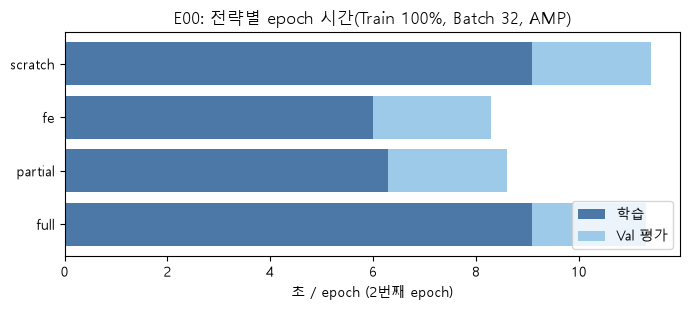

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(e00["전략"], e00["epoch2 학습(초)"], color="#4C78A8", label="학습")
ax.barh(e00["전략"], e00["Val 평가(초)"], left=e00["epoch2 학습(초)"], color="#9ECAE9", label="Val 평가")
ax.set_xlabel("초 / epoch (2번째 epoch)"); ax.invert_yaxis(); ax.legend(loc="lower right")
ax.set_title("E00: 전략별 epoch 시간(Train 100%, Batch 32, AMP)")
plt.tight_layout(); plt.savefig(FIGURES / "e00_epoch_time.png", dpi=110); plt.show()

### 5.1 읽는 법

- **FE가 가장 빠른 이유**: 역전파가 `fc`까지만 갑니다. 백본은 순전파만 하므로 계산이 줄어듭니다.
- **Partial FT**는 역전파가 `layer4`까지만 가서 Full보다 빠릅니다.
- **Scratch와 Full FT**는 계산량이 같습니다(같은 구조, 전체 학습). 시간이 거의 같아야 정상이고, 차이는 "초기 가중치"에서만 납니다.
- Val Macro F1은 2 epoch만 본 값이라 **성능 비교가 아닙니다.** 학습이 돌아가는지 확인하는 용도입니다.

In [10]:
per_epoch = (e00.set_index("전략")["epoch2 학습(초)"] + e00.set_index("전략")["Val 평가(초)"])
plan = pd.DataFrame({"epoch당(초)": per_epoch.round(1)})
for n in (20, 30, 40):
    plan[f"{n} epoch(분, 추정)"] = (per_epoch * n / 60).round(1)
plan

,epoch당(초),"20 epoch(분, 추정)","30 epoch(분, 추정)","40 epoch(분, 추정)"
전략,,,,
scratch,11.4,3.8,5.7,7.6
fe,8.3,2.8,4.2,5.5
partial,8.6,2.9,4.3,5.7
full,11.3,3.8,5.6,7.5


위 표의 "추정"은 2번째 epoch 시간 × epoch 수로 계산한 **상한 추정치**입니다. Early Stopping이 걸리면 더 짧아집니다.

## 6. E00 결론: 학습량 결정

- **epoch당 약 8~11초**(학습 + Val)입니다. GPU 메모리는 최대 약 620MB로 8GB의 8% 수준입니다. 시간과 메모리 모두 여유가 큽니다.
- 결정(D-019)
  - **기본 학습은 Train 100%** 로 합니다. 네 전략 모두 같습니다.
  - **Epoch 상한 50, Early Stopping patience 5**로 합니다. 최악의 경우 전략당 약 9분입니다.
  - Batch 32는 그대로 둡니다. 메모리가 남지만, 배치를 바꾸면 학습률과 일반화가 함께 바뀌므로 튜닝 단계의 변수로 남깁니다.
- 25·50·100% 비교(선택 항목)도 계산상으로는 충분히 가능합니다(전략 4개 × 비율 3개). 할지는 기본 학습(E01~E04) 결과를 보고 정합니다.
- 2 epoch 시점의 Val Macro F1(Scratch 0.50 / FE 0.61 / Partial 0.78 / Full 0.83)은 **학습이 정상적으로 돌아간다는 확인용**입니다. 순서가 가설(Partial ≈ Full > FE > Scratch)과 비슷하게 나왔지만, 2 epoch만 본 값이라 결론으로 쓰지 않습니다. Partial은 2번째 epoch에 Train 정확도가 오르는데 Val F1이 내려갔습니다. 본 학습에서 과적합이 빨리 오는지 지켜볼 지점입니다.
- **같은 seed라도 GPU 연산 방식만 바뀌면 점수가 움직입니다.** benchmark 모드와 결정적 모드의 2 epoch Val Macro F1이 Scratch 0.460 → 0.497, Full 0.839 → 0.827로 달랐습니다. 학습 초반이라 흔들림이 크게 보이는 것이지만, 최종 비교에서도 0.01~0.02 정도의 차이는 잡음일 수 있다는 뜻입니다. 최종 후보끼리 차이가 작으면 seed를 바꿔 반복해 보는 것(선택 항목 "여러 seed")을 검토합니다.